# Telecom Customer Churn Prediction
**Claudia Galdamez**

**DSC400-T301 Big Data,Tech and Algo**


For this assignment, I will use Apache Spark and scikit-learn to analyze customer churn in a telecom company. Customer churn happens when someone stops using a company's services.

The dataset includes information about how long customers have been with the company, their monthly charges, and the type of service they use. I will look for patterns in the data, clean it if needed, and build machine learning models to predict which customers might leave.

I will also compare the models using accuracy, precision, recall, and F1 scores. I will also use clustering to see whether customers can be grouped based on similar characteristics.

In [ ]:

# Install PySpark for working with larger datasets
!pip install pyspark -q


In [ ]:

# Import libraries for data analysis and machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import Spark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Import scikit-learn tools
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Start a Spark session
spark = SparkSession.builder \
    .appName("TelecomCustomerChurn") \
    .getOrCreate()

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Upload the telecom customer churn dataset
from google.colab import files

uploaded = files.upload()


Saving telecom_customer_churn.csv to telecom_customer_churn.csv


In [ ]:

# Load the CSV file into Spark
df = spark.read.csv(
    "telecom_customer_churn.csv",
    header=True,
    inferSchema=True
)

# Show the first 5 rows
df.show(5)

# Check the column names and data types
df.printSchema()

# Count the number of rows
print("Total rows:", df.count())


+------+---------------+------------+-----+
|Tenure|Monthly_Charges|Service_Type|Churn|
+------+---------------+------------+-----+
|    67|         115.41|    Internet|   No|
|    55|          97.76|    Multiple|   No|
|    62|          52.84|       Phone|   No|
|    18|          40.86|    Multiple|   No|
|    56|          81.29|       Phone|   No|
+------+---------------+------------+-----+
only showing top 5 rows
root
 |-- Tenure: integer (nullable = true)
 |-- Monthly_Charges: double (nullable = true)
 |-- Service_Type: string (nullable = true)
 |-- Churn: string (nullable = true)

Total rows: 10000


The dataset contains 10,000 customer records with four columns: Tenure, Monthly_Charges, Service_Type, and Churn.
Tenure and Monthly_Charges are numerical columns, while Service_Type and Churn contain categories. Churn is the column I will try to predict later.
The first five records show customers with different monthly charges and lengths of service. All five have a churn value of "No," but I will need to look at the full dataset to see how many customers actually left.

In [ ]:

# Check for missing values in each column
from pyspark.sql.functions import col, count, when

missing_values = df.select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in df.columns
])

missing_values.show()


+------+---------------+------------+-----+
|Tenure|Monthly_Charges|Service_Type|Churn|
+------+---------------+------------+-----+
|     0|              0|           0|    0|
+------+---------------+------------+-----+



I checked all four columns for missing values, and none were found. All 10,000 records have information for tenure, monthly charges, service type, and churn.
This makes the cleaning process easier since I won't need to replace or remove any missing values. I will still check for duplicates and inconsistent values before using the data for machine learning.

In [ ]:

# Look at the average, minimum, and maximum values
# for customer tenure and monthly charges

df.select("Tenure", "Monthly_Charges").describe().show()


+-------+-----------------+------------------+
|summary|           Tenure|   Monthly_Charges|
+-------+-----------------+------------------+
|  count|            10000|             10000|
|   mean|          35.8162| 74.98581399999998|
| stddev|20.60025375099691|25.958185292423185|
|    min|                1|             30.01|
|    max|               71|             120.0|
+-------+-----------------+------------------+



The average customer tenure is about 35.8 months (almost 3 years). Some customers have only been with the company for 1 month, while others have stayed for as long as 71 months.

The average monthly charge is about \$74.99. Bills are ranging from \$30.01 to \$120. I also noticed that the standard deviation for monthly charges is about \$25.96, which shows that customers are paying different amounts depending on their services.


In [ ]:

# Count customers who stayed or left
print("Customer Churn Counts:")
df.groupBy("Churn").count().show()

# Count customers by service type
print("Service Type Counts:")
df.groupBy("Service_Type").count().show()

# Calculate the percentage of customers who left
total_customers = df.count()

df.groupBy("Churn").count() \
    .withColumn(
        "Percentage",
        F.round(F.col("count") / total_customers * 100, 2)
    ).show()


Customer Churn Counts:
+-----+-----+
|Churn|count|
+-----+-----+
|   No| 8033|
|  Yes| 1967|
+-----+-----+

Service Type Counts:
+------------+-----+
|Service_Type|count|
+------------+-----+
|    Internet| 3015|
|       Phone| 2978|
|    Multiple| 4007|
+------------+-----+

+-----+-----+----------+
|Churn|count|Percentage|
+-----+-----+----------+
|   No| 8033|     80.33|
|  Yes| 1967|     19.67|
+-----+-----+----------+



Out of 10,000 customers, 8,033 stayed with the company and 1,967 left. That means about 80% stayed, while almost 20% canceled their service.
One thing that stood out was the difference between these two groups. Since most customers stayed, a machine learning model could get fairly high accuracy just by predicting "No" for everyone. This is why I will also look at precision, recall, and F1 scores instead of relying only on accuracy.
I also looked at the service types. Multiple services had the most customers with 4,007, followed by Internet with 3,015 and Phone with 2,978. The service types are fairly close in size, although Multiple is the largest group.
I still need to compare churn rates within each service type to see whether customers using certain services are more likely to leave.

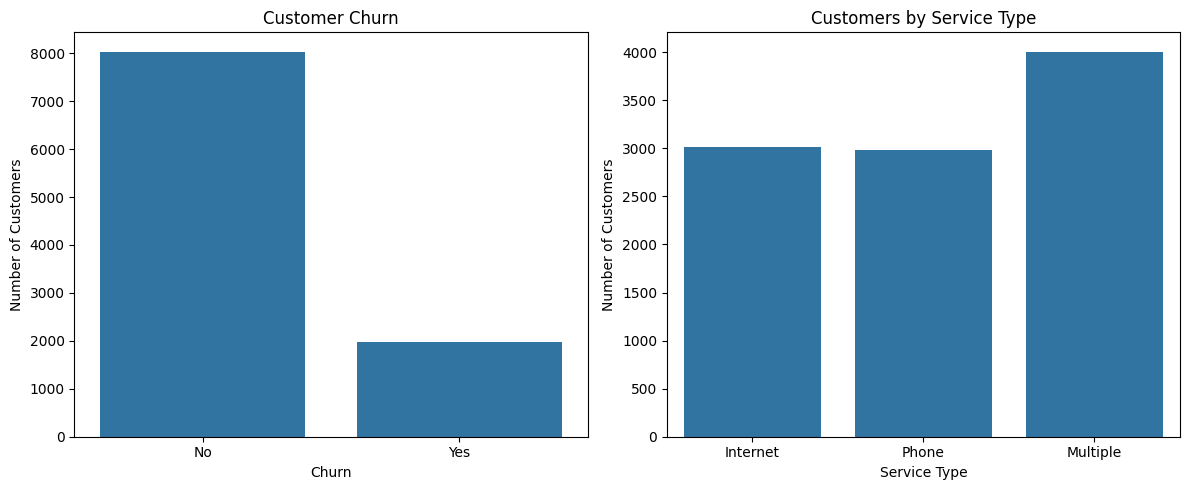

In [ ]:

# Convert the summary counts to Pandas for plotting
churn_counts = df.groupBy("Churn").count().toPandas()
service_counts = df.groupBy("Service_Type").count().toPandas()

# Create two charts to compare customer counts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Customers who stayed or left
sns.barplot(
    data=churn_counts,
    x="Churn",
    y="count",
    order=["No", "Yes"],
    ax=axes[0]
)

axes[0].set_title("Customer Churn")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Number of Customers")

# Chart 2: Customers by service type
sns.barplot(
    data=service_counts,
    x="Service_Type",
    y="count",
    ax=axes[1]
)

axes[1].set_title("Customers by Service Type")
axes[1].set_xlabel("Service Type")
axes[1].set_ylabel("Number of Customers")

# Adjust spacing and display both charts
plt.tight_layout()
plt.show()


The first graph shows a pretty big difference between customers who stayed and customers who left. About 80% stayed with the company, while only 20% left. This is something I will need to consider when evaluating my models because predicting the larger group could make the accuracy look better than it really is.
In the second graph, Multiple services has the most customers at 4,007. Internet and Phone are almost equal, with 3,015 and 2,978 customers.
One thing I noticed is that these graphs only show the number of customers in each group. They don't really explain why customers leave. I want to look at the churn rate for each service type next to see if there are any differences.

In [ ]:

# Count customers who left within each service type
service_churn = df.groupBy("Service_Type").agg(
    F.count("*").alias("Total_Customers"),
    F.sum(
        F.when(F.col("Churn") == "Yes", 1).otherwise(0)
    ).alias("Customers_Left")
)

# Calculate the churn percentage for each service type
service_churn = service_churn.withColumn(
    "Churn_Rate",
    F.round(
        F.col("Customers_Left") /
        F.col("Total_Customers") * 100, 2
    )
)

# Show service types with the highest churn rate first
service_churn.orderBy(F.desc("Churn_Rate")).show()


+------------+---------------+--------------+----------+
|Service_Type|Total_Customers|Customers_Left|Churn_Rate|
+------------+---------------+--------------+----------+
|    Multiple|           4007|           796|     19.87|
|       Phone|           2978|           583|     19.58|
|    Internet|           3015|           588|      19.5|
+------------+---------------+--------------+----------+



I compared the churn rates for all three service types to see whether certain customers were more likely to leave.
Multiple services had the highest churn rate at 19.87%, followed by Phone at 19.58% and Internet at 19.50%.
I was expecting to see a bigger difference between the service types, but they were almost identical. The difference between the highest and lowest churn rates was only 0.37 percentage points.
Based on these results, service type doesn't appear to have a strong relationship with customer churn on its own. I will keep it as a feature when building the models to see whether it helps with predictions.

## Data Cleaning

Before building the machine learning models, I need to check the dataset for duplicate records and values that might cause problems.
The missing value check showed that all four columns were complete. I will now check for duplicate rows and make sure the numerical and categorical values look reasonable.

In [ ]:

# Count the total number of records
total_rows = df.count()

# Count unique rows
unique_rows = df.dropDuplicates().count()

# Calculate how many rows are duplicates
duplicate_rows = total_rows - unique_rows

print("Total rows:", total_rows)
print("Unique rows:", unique_rows)
print("Duplicate rows:", duplicate_rows)


Total rows: 10000
Unique rows: 9981
Duplicate rows: 19


I checked the dataset for duplicate rows and found 19 out of 10,000 records. That leaves 9,981 unique combinations of values.
Since the dataset doesn't include customer IDs, I can't confirm whether these are duplicate customers or just customers with identical information. I decided to keep the records rather than remove data that might be valid.
The duplicate rows only make up 0.19% of the dataset, so I don't expect them to make a major difference in the overall analysis.

In [ ]:

# Check for negative tenure or monthly charges
invalid_values = df.filter(
    (F.col("Tenure") < 0) |
    (F.col("Monthly_Charges") < 0)
)

print("Records with negative values:", invalid_values.count())

# Check for unexpected service categories
print("Service Types:")
df.select("Service_Type").distinct().show()

# Check for unexpected churn categories
print("Churn Values:")
df.select("Churn").distinct().show()


Records with negative values: 0
Service Types:
+------------+
|Service_Type|
+------------+
|    Internet|
|       Phone|
|    Multiple|
+------------+

Churn Values:
+-----+
|Churn|
+-----+
|   No|
|  Yes|
+-----+



I checked for negative values in tenure and monthly charges, and none were found. I also checked the service types and churn categories to make sure the values were consistent.
Service_Type only contains Internet, Phone, and Multiple, while Churn only contains Yes and No. I didn't find any unexpected categories.
Since there were no missing values or negative numbers, I didn't need to make many changes to the original data. I also kept the 19 identical rows because there isn't a customer ID to confirm whether they are actual duplicates.
The next step is to create some additional features that might help the models identify customers who are more likely to leave.

## Feature Engineering

I wanted to create a couple of new features to see whether grouping customers by tenure and monthly charges would help identify churn patterns.
I will group customers based on how long they've been with the company and how much they pay each month. This should make it easier to compare customer behavior before building the machine learning models.

In [ ]:

# Create a copy with new customer features
df_features = df.withColumn(
    "Tenure_Group",
    F.when(F.col("Tenure") <= 12, "New")
     .when(F.col("Tenure") <= 36, "Established")
     .otherwise("Long-Term")
)

# Group customers based on their monthly charges
df_features = df_features.withColumn(
    "Charge_Level",
    F.when(F.col("Monthly_Charges") < 60, "Low")
     .when(F.col("Monthly_Charges") < 90, "Medium")
     .otherwise("High")
)

# Display the new columns
df_features.show(10)


+------+---------------+------------+-----+------------+------------+
|Tenure|Monthly_Charges|Service_Type|Churn|Tenure_Group|Charge_Level|
+------+---------------+------------+-----+------------+------------+
|    67|         115.41|    Internet|   No|   Long-Term|        High|
|    55|          97.76|    Multiple|   No|   Long-Term|        High|
|    62|          52.84|       Phone|   No|   Long-Term|         Low|
|    18|          40.86|    Multiple|   No| Established|         Low|
|    56|          81.29|       Phone|   No|   Long-Term|      Medium|
|    22|           62.4|    Multiple|   No| Established|      Medium|
|     8|         104.79|       Phone|   No|         New|        High|
|    11|          97.05|    Multiple|   No|         New|        High|
|    12|          54.88|    Multiple|   No|         New|         Low|
|    48|          31.53|       Phone|   No|   Long-Term|         Low|
+------+---------------+------------+-----+------------+------------+
only showing top 10 

I created two new columns, Tenure_Group and Charge_Level, using the information already in the dataset.
Tenure_Group separates customers into New, Established, and Long-Term groups. Charge_Level separates monthly bills into Low, Medium, and High.
Looking at the first 10 rows, the new categories appear to match the original values. For example, a customer with 67 months of tenure and a $115.41 monthly bill was placed in the Long-Term and High groups.
These new columns should make it easier to compare churn rates between different types of customers. I still need to check whether the groups actually show any differences.

In [ ]:

# Compare churn rates by tenure group
print("Churn by Tenure Group:")

df_features.groupBy("Tenure_Group").agg(
    F.count("*").alias("Total_Customers"),
    F.round(
        F.avg(
            F.when(F.col("Churn") == "Yes", 1).otherwise(0)
        ) * 100, 2
    ).alias("Churn_Rate")
).orderBy("Tenure_Group").show()

# Compare churn rates by monthly charge level
print("Churn by Charge Level:")

df_features.groupBy("Charge_Level").agg(
    F.count("*").alias("Total_Customers"),
    F.round(
        F.avg(
            F.when(F.col("Churn") == "Yes", 1).otherwise(0)
        ) * 100, 2
    ).alias("Churn_Rate")
).orderBy("Charge_Level").show()


Churn by Tenure Group:
+------------+---------------+----------+
|Tenure_Group|Total_Customers|Churn_Rate|
+------------+---------------+----------+
| Established|           3343|     20.25|
|   Long-Term|           4901|     19.38|
|         New|           1756|     19.36|
+------------+---------------+----------+

Churn by Charge Level:
+------------+---------------+----------+
|Charge_Level|Total_Customers|Churn_Rate|
+------------+---------------+----------+
|        High|           3340|     19.25|
|         Low|           3358|     19.92|
|      Medium|           3302|     19.84|
+------------+---------------+----------+



I compared churn rates across the new tenure and monthly charge groups to see if there were any noticeable differences.
For tenure, Established customers had the highest churn rate at 20.25%, followed by Long-Term customers at 19.38% and New customers at 19.36%. I expected newer customers to have a higher churn rate, but that wasn't the case. The difference between the highest and lowest groups was only 0.89 percentage points.
Monthly charges showed a similar pattern. Customers in the Low charge group had the highest churn rate at 19.92%, followed by Medium at 19.84% and High at 19.25%.
So far, none of these groups seem to have a strong relationship with churn. I'll still include them when testing the models, but I'm not expecting them to make a big difference based on these results.

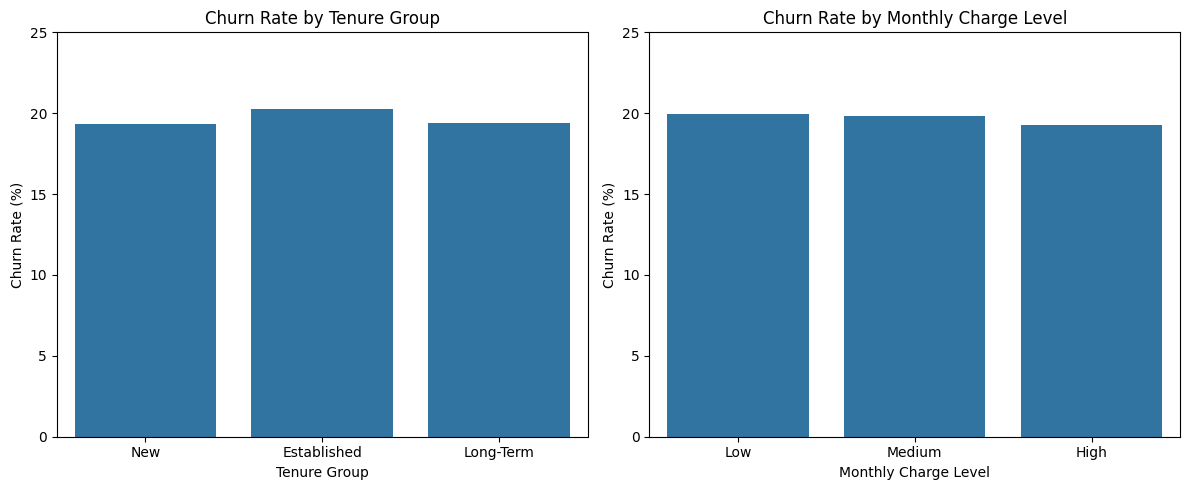

In [ ]:

# Calculate churn rates for each tenure group
tenure_churn = df_features.groupBy("Tenure_Group").agg(
    F.avg(
        F.when(F.col("Churn") == "Yes", 1).otherwise(0)
    ).alias("Churn_Rate")
).toPandas()

# Convert churn rates to percentages
tenure_churn["Churn_Rate"] *= 100

# Calculate churn rates for each charge level
charge_churn = df_features.groupBy("Charge_Level").agg(
    F.avg(
        F.when(F.col("Churn") == "Yes", 1).otherwise(0)
    ).alias("Churn_Rate")
).toPandas()

# Convert churn rates to percentages
charge_churn["Churn_Rate"] *= 100

# Create two bar charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Churn by tenure group
sns.barplot(
    data=tenure_churn,
    x="Tenure_Group",
    y="Churn_Rate",
    order=["New", "Established", "Long-Term"],
    ax=axes[0]
)

axes[0].set_title("Churn Rate by Tenure Group")
axes[0].set_xlabel("Tenure Group")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_ylim(0, 25)

# Chart 2: Churn by monthly charge level
sns.barplot(
    data=charge_churn,
    x="Charge_Level",
    y="Churn_Rate",
    order=["Low", "Medium", "High"],
    ax=axes[1]
)

axes[1].set_title("Churn Rate by Monthly Charge Level")
axes[1].set_xlabel("Monthly Charge Level")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].set_ylim(0, 25)

# Display both charts
plt.tight_layout()
plt.show()


Looking at both graphs, I noticed that the churn rates are pretty similar across all the groups. Established customers had the highest churn rate at 20.25%, but New and Long-Term customers were both around 19.4%.
The monthly charge groups showed the same pattern. Customers paying lower monthly charges had a slightly higher churn rate at 19.92%, while customers in the High group had the lowest at 19.25%.
I was expecting to see a bigger difference, especially between newer and long-term customers. So far, tenure and monthly charges don't seem to explain much about why customers leave. I'm curious to see whether the machine learning models will find patterns that aren't as obvious in these graphs.

## Supervised Machine Learning – Scikit-learn

I will start with Logistic Regression to predict which customers might leave the company. Since customers either leave or stay, this model makes sense to use.

I will split the data into 80% for training and 20% for testing. I will also make sure both groups have about the same percentage of customers who left so the results are easier to compare.

In [ ]:

# Convert the Spark dataset to Pandas
pdf = df_features.toPandas()

# Separate the input features from churn
X = pdf.drop(columns=["Churn"])

# Convert churn into numbers
# No = 0 and Yes = 1
y = pdf["Churn"].map({"No": 0, "Yes": 1})

# Split the data into training and testing sets
# Stratify keeps the churn percentages similar
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the number of records in each set
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Check the churn percentages
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")


Training records: 8000
Testing records: 2000
Training churn rate: 19.68 %
Testing churn rate: 19.65 %


I split the dataset into 8,000 training records and 2,000 testing records.
The training set had a churn rate of 19.68%, while the testing set had 19.65%. These percentages are almost identical, so both sets have a similar proportion of customers who stayed and left.
I used stratified sampling because the dataset has a lot more customers who stayed than customers who left. This should make the model comparison more consistent.

## Preparing Features for Logistic Regression

Some of the columns contain text, such as Internet, Phone, Multiple, and the customer groups I created earlier. Scikit-learn needs these values converted into numerical features.
I will use one-hot encoding for the categorical columns and standard scaling for tenure and monthly charges. The transformations will be fitted using the training data so that information from the testing set doesn't influence the model.

In [ ]:

# Import tools for encoding and scaling
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = ["Tenure", "Monthly_Charges"]

categorical_features = [
    "Service_Type",
    "Tenure_Group",
    "Charge_Level"
]

# Scale numbers and encode categories
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Create a pipeline for preprocessing and Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model using only the training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [ ]:

# Make predictions using the testing data
y_pred = logistic_model.predict(X_test)

# Calculate the model's performance scores
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display the results
print("Scikit-learn Logistic Regression Results")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

# Show the full classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))


Scikit-learn Logistic Regression Results
Accuracy: 0.8035
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.80      1.00      0.89      1607
        Left       0.00      0.00      0.00       393

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.45      2000
weighted avg       0.65      0.80      0.72      2000



My Logistic Regression model had an accuracy of 80.35%, which seemed pretty good at first. But when I looked at the other scores, I noticed that precision, recall, and F1 were all 0 for customers who left.

The model predicted that every customer would stay. It correctly predicted all 1,607 customers who stayed but missed all 393 customers who left. The accuracy was still high because most customers in the dataset stayed.

This helped me see why accuracy alone doesn't show the whole picture. The goal is to predict which customers might leave, and right now the model isn't identifying any of them. Recall is important also because I want to see how many customers who actually left the model can catch.

I need to check the confusion matrix and try adjusting the model to see if I can get better results.

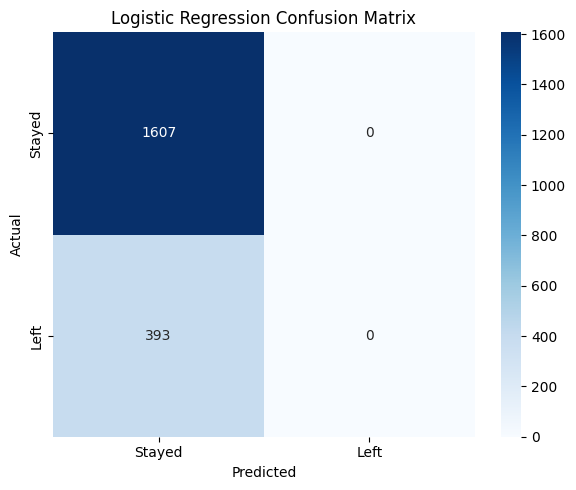

In [ ]:

# Create a confusion matrix for Logistic Regression
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix as a heatmap
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


The confusion matrix helped me understand why my model had 80.35% accuracy but a recall of zero. Out of 2,000 customers, it correctly predicted that 1,607 would stay but missed all 393 customers who actually left. I was surprised that it didn't identify a single customer who canceled their service.

Since most customers stayed, the model seemed to favor that group. This wouldn't be very useful for a telecom company trying to identify customers who might leave. I looked into ways to handle this and found that Scikit-learn has a balanced class weight option that gives more weight to the smaller group (Scikit-learn developers, n.d.).

I will try this option next to see if the model can identify more customers who leave.

In [ ]:

# Create a Logistic Regression model with balanced class weights
balanced_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the balanced model
balanced_model.fit(X_train, y_train)

# Predict churn using the testing data
y_pred_balanced = balanced_model.predict(X_test)

# Calculate the evaluation scores
print("Balanced Logistic Regression Results")
print("Accuracy:", round(
    accuracy_score(y_test, y_pred_balanced), 4
))
print("Precision:", round(
    precision_score(y_test, y_pred_balanced, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred_balanced, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, y_pred_balanced, zero_division=0), 4
))

# Show the full classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Stayed", "Left"],
    zero_division=0
))


Balanced Logistic Regression Results
Accuracy: 0.4995
Precision: 0.1935
Recall: 0.4885
F1 Score: 0.2773

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.80      0.50      0.62      1607
        Left       0.19      0.49      0.28       393

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.45      2000
weighted avg       0.68      0.50      0.55      2000



After adjusting the class weights, I noticed a big difference in the results. My first model had 80.35% accuracy but didn't identify any customers who left. The balanced model dropped to 49.95% accuracy, but recall improved to 48.85%. This means it was able to identify almost half of the customers who actually left.

Precision was still low at 19.35%, meaning the model was also predicting that many customers would leave when they actually stayed.

Comparing both models helped me understand the difference between accuracy and recall. The balanced model caught more customers who left, but it also made more mistakes. Neither model did very well at predicting churn overall.

Looking back at my earlier graphs, I didn't see much difference in churn rates based on tenure, monthly charges, or service type. This could be one reason the models are struggling to find patterns that help predict which customers will leave.

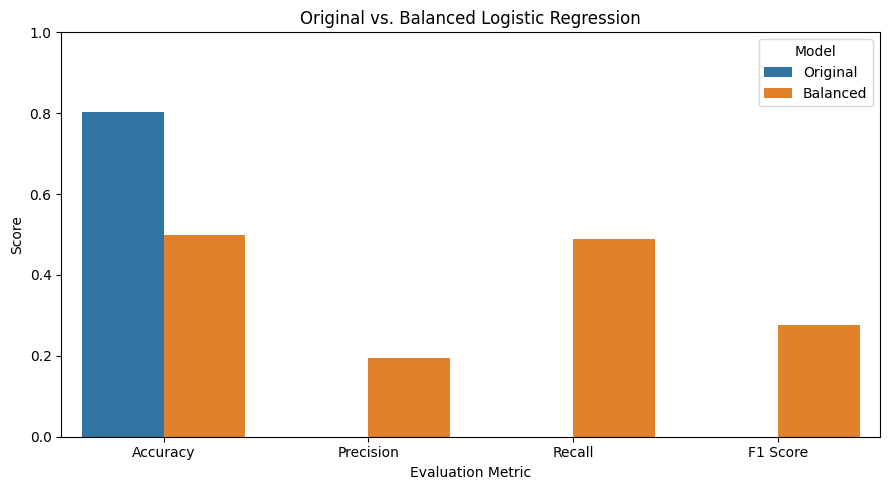

In [ ]:

# Store the evaluation results for both models
model_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Original": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ],
    "Balanced": [
        accuracy_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_balanced, zero_division=0),
        recall_score(y_test, y_pred_balanced, zero_division=0),
        f1_score(y_test, y_pred_balanced, zero_division=0)
    ]
})

# Reshape the results for plotting
results_long = model_results.melt(
    id_vars="Metric",
    var_name="Model",
    value_name="Score"
)

# Compare the model scores
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Original vs. Balanced Logistic Regression")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.legend(title="Model")

plt.tight_layout()
plt.show()


The graph shows a pretty big difference between the two models. The original model had higher accuracy at 80.35%, but it didn't correctly identify any customers who left.
After balancing the class weights, recall increased to 48.85% and F1 improved to 27.73%. However, accuracy dropped to 49.95%, and precision was only 19.35%.
What stood out to me was how much the results changed just by adjusting the class weights. The balanced model found more customers who left, but it also incorrectly flagged more customers who stayed.
Neither model performed particularly well at predicting churn. Based on the patterns I found earlier, I think the limited customer information could be part of the problem.

## PySpark MLlib – Logistic Regression

Next, I will use PySpark MLlib to predict customer churn and compare the results with scikit-learn. I will use the same training and testing data to make the comparison fair. PySpark uses Spark DataFrames and pipelines to work with data, especially larger datasets (Apache Spark, n.d.).

In [ ]:

# Import PySpark machine learning tools
from pyspark.ml import Pipeline as SparkPipeline
from pyspark.ml.classification import LogisticRegression as SparkLogisticRegression
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder as SparkOneHotEncoder,
    VectorAssembler,
    StandardScaler as SparkStandardScaler
)

# Use the same training and testing records
# that were used for scikit-learn
spark_train_pdf = X_train.copy()
spark_train_pdf["label"] = y_train

spark_test_pdf = X_test.copy()
spark_test_pdf["label"] = y_test

# Convert the data into Spark DataFrames
spark_train = spark.createDataFrame(spark_train_pdf)
spark_test = spark.createDataFrame(spark_test_pdf)

# Check the number of records
print("Spark training records:", spark_train.count())
print("Spark testing records:", spark_test.count())

# Check how many customers stayed or left
spark_train.groupBy("label").count().show()


Spark training records: 8000
Spark testing records: 2000
+-----+-----+
|label|count|
+-----+-----+
|    0| 6426|
|    1| 1574|
+-----+-----+



I converted the training and testing data into Spark DataFrames. The training set has 8,000 records, and the testing set has 2,000, which matches my earlier scikit-learn split.
Out of the 8,000 training records, 6,426 customers stayed and 1,574 left. This is the same class imbalance I saw earlier.
I will use these records to train a Logistic Regression model in PySpark and compare its results with scikit-learn.

##Preparing Features for PySpark

Before training the model, I need to convert the categorical columns into numbers and combine the features into one column.
I will use StringIndexer and OneHotEncoder for the categories, followed by VectorAssembler to combine the features. I will also scale the numerical columns.
The preprocessing steps will be fitted on the training data and then applied to the testing data (Apache Spark, n.d.).

In [ ]:

# Identify the categorical columns
categorical_cols = [
    "Service_Type",
    "Tenure_Group",
    "Charge_Level"
]

# Convert text categories into numerical indexes
indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_Index",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

# Apply one-hot encoding to the indexed columns
encoder = SparkOneHotEncoder(
    inputCols=[c + "_Index" for c in categorical_cols],
    outputCols=[c + "_Encoded" for c in categorical_cols]
)

# Combine numerical columns for scaling
numeric_assembler = VectorAssembler(
    inputCols=["Tenure", "Monthly_Charges"],
    outputCol="Numeric_Features"
)

# Standardize the numerical features
scaler = SparkStandardScaler(
    inputCol="Numeric_Features",
    outputCol="Scaled_Numeric_Features",
    withMean=True,
    withStd=True
)

# Combine all features into one vector
feature_assembler = VectorAssembler(
    inputCols=[
        "Scaled_Numeric_Features",
        "Service_Type_Encoded",
        "Tenure_Group_Encoded",
        "Charge_Level_Encoded"
    ],
    outputCol="features"
)

# Create the preprocessing pipeline
spark_preprocessing = SparkPipeline(
    stages=indexers + [
        encoder,
        numeric_assembler,
        scaler,
        feature_assembler
    ]
)

# Fit preprocessing using training data only
spark_preprocessor_model = spark_preprocessing.fit(spark_train)

# Apply preprocessing to training and testing data
spark_train_ready = spark_preprocessor_model.transform(spark_train)
spark_test_ready = spark_preprocessor_model.transform(spark_test)

# Display the prepared features
spark_train_ready.select("label", "features").show(5, truncate=False)

print("PySpark feature preparation completed!")


+-----+-----------------------------------------------------------------------+
|label|features                                                               |
+-----+-----------------------------------------------------------------------+
|1    |(11,[0,1,3,6,10],[-0.1426460777116908,0.24215437922298064,1.0,1.0,1.0])|
|1    |(11,[0,1,4,5,10],[1.0243918854996925,-0.351226890511503,1.0,1.0,1.0])  |
|0    |(11,[0,1,3,6,9],[-0.6289118957164339,0.5811190863322041,1.0,1.0,1.0])  |
|0    |(11,[0,1,4,5,9],[1.55928428530491,1.3849055558098842,1.0,1.0,1.0])     |
|0    |(11,[0,1,4,5,9],[1.0243918854996925,1.4238980790650455,1.0,1.0,1.0])   |
+-----+-----------------------------------------------------------------------+
only showing top 5 rows
PySpark feature preparation completed!


In [ ]:

# Create a Logistic Regression model in PySpark
spark_lr = SparkLogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100,
    regParam=0.0
)

# Train the model
spark_lr_model = spark_lr.fit(spark_train_ready)

# Make predictions using the testing data
spark_predictions = spark_lr_model.transform(spark_test_ready)

# Display actual and predicted churn
spark_predictions.select(
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)

print("PySpark Logistic Regression model trained successfully!")


+-----+----------+----------------------------------------+
|label|prediction|probability                             |
+-----+----------+----------------------------------------+
|0    |0.0       |[0.832663646070846,0.16733635392915402] |
|0    |0.0       |[0.7915201394033686,0.20847986059663137]|
|0    |0.0       |[0.7987110700097066,0.20128892999029335]|
|0    |0.0       |[0.8106064287763587,0.1893935712236413] |
|0    |0.0       |[0.7851427812863166,0.21485721871368335]|
|0    |0.0       |[0.8044358582623024,0.19556414173769765]|
|0    |0.0       |[0.8037845640326928,0.19621543596730717]|
|0    |0.0       |[0.8049872988817981,0.1950127011182019] |
|0    |0.0       |[0.7988023350302375,0.20119766496976255]|
|0    |0.0       |[0.8114155673657407,0.18858443263425928]|
+-----+----------+----------------------------------------+
only showing top 10 rows
PySpark Logistic Regression model trained successfully!


The PySpark Logistic Regression model ran successfully, and I was able to look at its predictions. In the first 10 rows, all customers had a churn value of 0, meaning they stayed. The model also predicted that they would stay.

I noticed that the chances of these customers leaving were only around 17% to 21%. Since these percentages were below 50%, the model predicted 0 for each customer.

So far, the predictions look correct for these 10 customers, but I still need to check the full testing dataset to see how well the model predicts customers who actually left.

## PySpark Model Evaluation


I will evaluate the PySpark model using accuracy, precision, recall, and F1 score.
I want to see whether PySpark performs differently from scikit-learn, especially when predicting customers who left. The original scikit-learn model had 80.35% accuracy but missed every customer who canceled their service.

In [ ]:

# Import PySpark evaluation tools
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Create evaluators for the classification metrics
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="precisionByLabel",
    metricLabel=1.0
)

recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="recallByLabel",
    metricLabel=1.0
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="fMeasureByLabel",
    metricLabel=1.0
)

# Calculate the model scores
spark_accuracy = accuracy_evaluator.evaluate(spark_predictions)
spark_precision = precision_evaluator.evaluate(spark_predictions)
spark_recall = recall_evaluator.evaluate(spark_predictions)
spark_f1 = f1_evaluator.evaluate(spark_predictions)

# Display the results
print("PySpark Logistic Regression Results")
print("Accuracy:", round(spark_accuracy, 4))
print("Precision:", round(spark_precision, 4))
print("Recall:", round(spark_recall, 4))
print("F1 Score:", round(spark_f1, 4))

# Check how many customers were predicted to stay or leave
print("\nPrediction Counts:")
spark_predictions.groupBy("prediction").count().show()


PySpark Logistic Regression Results
Accuracy: 0.8035
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Prediction Counts:
+----------+-----+
|prediction|count|
+----------+-----+
|       0.0| 2000|
+----------+-----+



The PySpark model had an accuracy of 80.35%, which was exactly the same as my original scikit-learn model.
However, precision, recall, and F1 were all zero. When I checked the prediction counts, I found that PySpark predicted all 2,000 customers would stay.
I was curious whether PySpark would give different results, but both models ended up making the same predictions. Neither model identified any customers who actually left.
This makes sense when looking back at my earlier analysis. The churn rates were almost identical across service types, tenure groups, and monthly charge levels. The models don't seem to have enough useful information to separate customers who leave from those who stay.
Using PySpark allowed me to work with the data through Spark's machine learning tools, but it didn't improve the predictions.

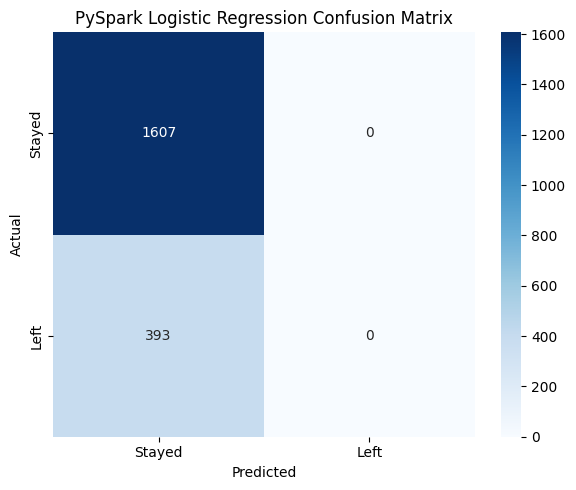

In [ ]:

# Convert Spark predictions to Pandas for visualization
spark_cm_pdf = spark_predictions.select(
    "label", "prediction"
).toPandas()

# Calculate the confusion matrix
cm_spark = confusion_matrix(
    spark_cm_pdf["label"],
    spark_cm_pdf["prediction"],
    labels=[0, 1]
)

# Display the confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_spark,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.title("PySpark Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


The confusion matrix shows that PySpark predicted all 2,000 customers would stay. It correctly identified 1,607 customers who stayed but missed all 393 customers who actually left.
This was exactly the same result I got with the original scikit-learn model. Both models had 80.35% accuracy, but neither identified any customers who canceled their service.
I was expecting some differences between the two models, but the results were identical. This makes me think the limited information in the dataset is making churn difficult to predict, regardless of which library I use.

## Unsupervised Learning – K-means Clustering

For this part, I will use K-means clustering to see whether customers can be separated into groups based on their characteristics.
Instead of predicting whether someone will leave, K-means looks for similarities between customers. I will use tenure, monthly charges, and service type to create the clusters.
After creating the groups, I will compare their churn rates to see whether any cluster has more customers leaving than the others (Apache Spark, n.d.).

In [ ]:

# Import PySpark K-means clustering
from pyspark.ml.clustering import KMeans

# Create a separate dataset for clustering
# Churn is not included as an input feature
cluster_data = df_features.select(
    "Tenure",
    "Monthly_Charges",
    "Service_Type",
    "Churn"
)

# Convert service types into numerical indexes
service_indexer = StringIndexer(
    inputCol="Service_Type",
    outputCol="Service_Index"
)

# One-hot encode the service types
service_encoder = SparkOneHotEncoder(
    inputCols=["Service_Index"],
    outputCols=["Service_Encoded"]
)

# Combine numerical columns
cluster_numeric_assembler = VectorAssembler(
    inputCols=["Tenure", "Monthly_Charges"],
    outputCol="Cluster_Numeric"
)

# Scale the numerical columns
cluster_scaler = SparkStandardScaler(
    inputCol="Cluster_Numeric",
    outputCol="Cluster_Scaled",
    withMean=True,
    withStd=True
)

# Combine the features for clustering
cluster_assembler = VectorAssembler(
    inputCols=["Cluster_Scaled", "Service_Encoded"],
    outputCol="cluster_features"
)

# Create the preprocessing pipeline
cluster_pipeline = SparkPipeline(stages=[
    service_indexer,
    service_encoder,
    cluster_numeric_assembler,
    cluster_scaler,
    cluster_assembler
])

# Prepare the data
cluster_model = cluster_pipeline.fit(cluster_data)
cluster_ready = cluster_model.transform(cluster_data)

# Display the prepared features
cluster_ready.select(
    "Tenure",
    "Monthly_Charges",
    "Service_Type",
    "cluster_features"
).show(5, truncate=False)

print("Clustering data prepared successfully!")


+------+---------------+------------+-------------------------------------------------+
|Tenure|Monthly_Charges|Service_Type|cluster_features                                 |
+------+---------------+------------+-------------------------------------------------+
|67    |115.41         |Internet    |[1.5137580525429584,1.5572808940461182,0.0,1.0]  |
|55    |97.76          |Multiple    |[0.9312409561494597,0.8773412217936143,1.0,0.0]  |
|62    |52.84          |Phone       |[1.271042595712334,-0.8531341367096432,0.0,0.0]  |
|18    |40.86          |Multiple    |[-0.8648534243971613,-1.3146455969694169,1.0,0.0]|
|56    |81.29          |Phone       |[0.9797840475155846,0.24285927267187235,0.0,0.0] |
+------+---------------+------------+-------------------------------------------------+
only showing top 5 rows
Clustering data prepared successfully!


## Preparing Data for K-means

I prepared the data for K-means by scaling tenure and monthly charges and changing service types into numbers. Looking at the first five rows, I can see how the customer information was converted into values the model can use.

Some values are negative because they are below the average, while positive values are above it. I left churn out because I want K-means to group customers based on things like how long they've been with the company, how much they pay, and what services they use. Later, I can compare the groups to see if any have higher churn rates.

In [ ]:

# Create a K-means model with 3 clusters
kmeans = KMeans(
    featuresCol="cluster_features",
    predictionCol="Cluster",
    k=3,
    seed=42
)

# Train the clustering model
kmeans_model = kmeans.fit(cluster_ready)

# Assign customers to clusters
cluster_predictions = kmeans_model.transform(cluster_ready)

# Count customers in each cluster
print("Customers in Each Cluster:")
cluster_predictions.groupBy("Cluster").count() \
    .orderBy("Cluster").show()

# Show the first 10 customer assignments
print("Sample Customer Clusters:")
cluster_predictions.select(
    "Tenure",
    "Monthly_Charges",
    "Service_Type",
    "Cluster"
).show(10)


Customers in Each Cluster:
+-------+-----+
|Cluster|count|
+-------+-----+
|      0| 3800|
|      1| 3049|
|      2| 3151|
+-------+-----+

Sample Customer Clusters:
+------+---------------+------------+-------+
|Tenure|Monthly_Charges|Service_Type|Cluster|
+------+---------------+------------+-------+
|    67|         115.41|    Internet|      0|
|    55|          97.76|    Multiple|      0|
|    62|          52.84|       Phone|      0|
|    18|          40.86|    Multiple|      1|
|    56|          81.29|       Phone|      0|
|    22|           62.4|    Multiple|      1|
|     8|         104.79|       Phone|      2|
|    11|          97.05|    Multiple|      2|
|    12|          54.88|    Multiple|      1|
|    48|          31.53|       Phone|      1|
+------+---------------+------------+-------+
only showing top 10 rows


K-means divided the 10,000 customers into three groups. Cluster 0 was the largest with 3,800 customers, followed by Cluster 2 with 3,151 and Cluster 1 with 3,049.

Looking at the first 10 rows, I noticed that some customers were placed in the same cluster even though they had different monthly charges and service types. For example, the first three customers were all in Cluster 0, but their monthly charges ranged from $52.84 to $115.41.

This shows that K-means is looking at several customer features together instead of just one. Next, I will compare the averages for each cluster to get a better idea of what makes these groups different.

## Analyzing Customer Segments

Now that K-means has assigned customers to three clusters, I want to see what makes each group different.
I will compare their average tenure, monthly charges, and churn rates. This should help me understand whether the clusters represent different types of customers and whether any group has a higher percentage of customers leaving.

In [ ]:

# Calculate customer statistics for each cluster
cluster_summary = cluster_predictions.groupBy("Cluster").agg(
    F.count("*").alias("Total_Customers"),

    F.round(
        F.avg("Tenure"), 2
    ).alias("Avg_Tenure"),

    F.round(
        F.avg("Monthly_Charges"), 2
    ).alias("Avg_Monthly_Charges"),

    F.round(
        F.avg(
            F.when(F.col("Churn") == "Yes", 1).otherwise(0)
        ) * 100, 2
    ).alias("Churn_Rate")
)

# Display the results by cluster
cluster_summary.orderBy("Cluster").show()


+-------+---------------+----------+-------------------+----------+
|Cluster|Total_Customers|Avg_Tenure|Avg_Monthly_Charges|Churn_Rate|
+-------+---------------+----------+-------------------+----------+
|      0|           3800|      57.4|               75.1|      19.5|
|      1|           3049|     22.43|              50.38|     19.58|
|      2|           3151|     22.74|              98.65|     19.96|
+-------+---------------+----------+-------------------+----------+



After comparing the three clusters, I noticed some clear differences in tenure and monthly charges.
Cluster 0 had the longest-term customers, with an average tenure of 57.4 months and monthly charges of \$75.10.
Clusters 1 and 2 had similar average tenure, around 22 months, but their monthly charges were very different. Cluster 1 averaged $50.38, while Cluster 2 averaged \$98.65.
What surprised me was that the churn rates were still almost identical. Cluster 2 had the highest churn rate at 19.96%, while Cluster 0 had the lowest at 19.50%.
K-means was able to separate customers based on their characteristics, but these groups didn't show much difference in churn. This is similar to what I found with the supervised learning models.

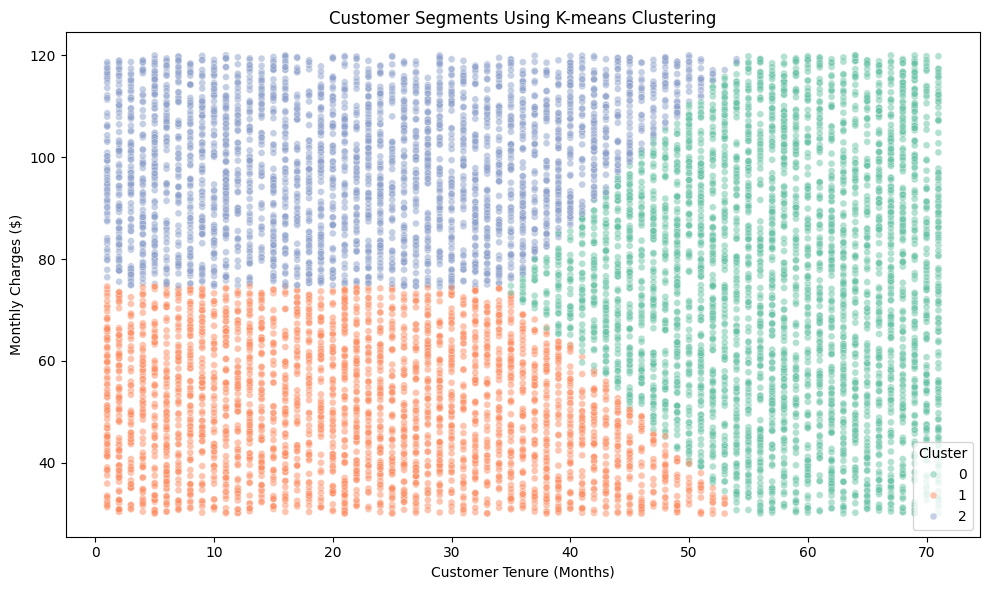

In [ ]:

# Convert cluster results to Pandas for visualization
cluster_pdf = cluster_predictions.select(
    "Tenure",
    "Monthly_Charges",
    "Cluster"
).toPandas()

# Create a scatterplot of customer clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cluster_pdf,
    x="Tenure",
    y="Monthly_Charges",
    hue="Cluster",
    palette="Set2",
    alpha=0.5,
    s=25
)

# Add labels and title
plt.title("Customer Segments Using K-means Clustering")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Monthly Charges ($)")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()


Looking at the graph, I noticed three patterns:
- Cluster 0 (green): Mostly longer-term customers, with monthly charges spread across a wide range.
- Cluster 1 (orange): Mostly customers with shorter tenure and lower monthly charges.
- Cluster 2 (purple): Mostly customers with shorter tenure and higher monthly charges.
The boundaries aren't perfectly straight because K-means considered service type along with tenure and monthly charges.

In [ ]:

# Import the clustering evaluation tool
from pyspark.ml.evaluation import ClusteringEvaluator

# Set up the silhouette score evaluator
cluster_evaluator = ClusteringEvaluator(
    featuresCol="cluster_features",
    predictionCol="Cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

# Calculate the silhouette score
silhouette_score = cluster_evaluator.evaluate(
    cluster_predictions
)

# Display the result
print("K-means Silhouette Score:", round(silhouette_score, 4))


K-means Silhouette Score: 0.4436


K-means Clustering Evaluation
My K-means model had a silhouette score of 0.4436. This suggests that the three clusters have some separation, but they aren't completely distinct.
Looking back at the scatterplot, this makes sense because I could see some overlap between the groups, especially around customers with 40 to 55 months of tenure.
K-means did a reasonable job separating customers based on their tenure and monthly charges. However, the churn rates were almost identical across the clusters, ranging from 19.50% to 19.96%.
The clusters might be useful for understanding different customer groups, but they don't appear to be very useful for identifying customers who are likely to leave.

## Comparing Different Numbers of Clusters


I started with three clusters, but I wanted to check whether using a different number would separate the customers better.
I will test K-means with 2 through 5 clusters and compare their silhouette scores. This should help me decide whether three clusters is a reasonable choice for this dataset.

Clusters: 2, Silhouette Score: 0.4368
Clusters: 3, Silhouette Score: 0.4436
Clusters: 4, Silhouette Score: 0.4588
Clusters: 5, Silhouette Score: 0.4387


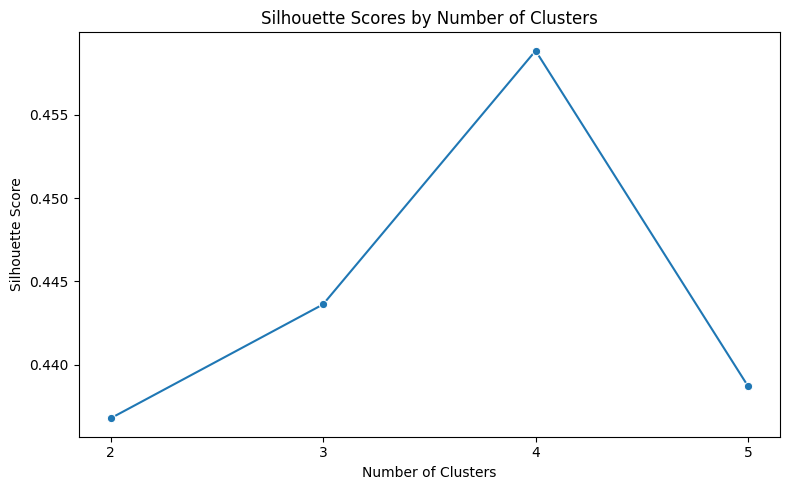

In [ ]:

# Store silhouette scores for different cluster counts
cluster_scores = []

# Test K-means using 2 through 5 clusters
for k in range(2, 6):

    # Create and train the K-means model
    test_kmeans = KMeans(
        featuresCol="cluster_features",
        predictionCol="Cluster",
        k=k,
        seed=42
    )

    test_model = test_kmeans.fit(cluster_ready)

    # Assign customers to clusters
    test_predictions = test_model.transform(cluster_ready)

    # Calculate the silhouette score
    score = cluster_evaluator.evaluate(test_predictions)

    # Save the result
    cluster_scores.append((k, score))

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Convert the results to a Pandas DataFrame
cluster_scores_df = pd.DataFrame(
    cluster_scores,
    columns=["Clusters", "Silhouette_Score"]
)

# Create a graph to compare the scores
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=cluster_scores_df,
    x="Clusters",
    y="Silhouette_Score",
    marker="o"
)

plt.title("Silhouette Scores by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks([2, 3, 4, 5])

plt.tight_layout()
plt.show()


## Comparing K-means Cluster Counts

I tested K-means with 2, 3, 4, and 5 clusters to see which one worked best. Four clusters had the highest silhouette score at 0.4588. Three clusters scored 0.4436, two scored 0.4368, and five scored 0.4387.

I thought adding more clusters might improve the results, but the score actually dropped when I tried five. Four clusters worked best out of the ones I tested, although the scores were pretty close.

The results show that there are some differences between the customer groups, but they aren't completely separate. I will continue with four clusters and look at the customer averages to see what makes each group different and whether any of them have higher churn rates.

In [ ]:

# Train a new K-means model using 4 clusters
kmeans_4 = KMeans(
    featuresCol="cluster_features",
    predictionCol="Cluster",
    k=4,
    seed=42
)

# Fit the model and assign customers to clusters
kmeans_4_model = kmeans_4.fit(cluster_ready)
clusters_4 = kmeans_4_model.transform(cluster_ready)

# Compare customer characteristics and churn rates
cluster_4_summary = clusters_4.groupBy("Cluster").agg(
    F.count("*").alias("Total_Customers"),

    F.round(
        F.avg("Tenure"), 2
    ).alias("Avg_Tenure"),

    F.round(
        F.avg("Monthly_Charges"), 2
    ).alias("Avg_Monthly_Charges"),

    F.round(
        F.avg(
            F.when(F.col("Churn") == "Yes", 1).otherwise(0)
        ) * 100, 2
    ).alias("Churn_Rate")
)

# Display the four customer groups
cluster_4_summary.orderBy("Cluster").show()


+-------+---------------+----------+-------------------+----------+
|Cluster|Total_Customers|Avg_Tenure|Avg_Monthly_Charges|Churn_Rate|
+-------+---------------+----------+-------------------+----------+
|      0|           2485|     53.84|              52.64|     18.59|
|      1|           2464|     17.89|               51.8|     19.89|
|      2|           2516|      53.5|              97.46|     20.11|
|      3|           2535|     18.02|              97.12|     20.08|
+-------+---------------+----------+-------------------+----------+



After testing different cluster counts, I used four clusters because that model had the highest silhouette score at 0.4588.

The four groups were almost equal in size, with around 2,500 customers each. Clusters 0 and 2 had longer-term customers, averaging around 53 months of tenure. Clusters 1 and 3 had customers with much shorter tenure, averaging around 18 months.

Monthly charges also separated the groups. Clusters 0 and 1 averaged around $52 per month, while Clusters 2 and 3 averaged around \$97.
What I found interesting was that the churn rates were still very similar. Cluster 2 had the highest churn rate at 20.11%, while Cluster 0 had the lowest at 18.59%.

The four-cluster model did a better job separating customers based on their characteristics, but it still didn't identify a group with a noticeably higher churn rate.

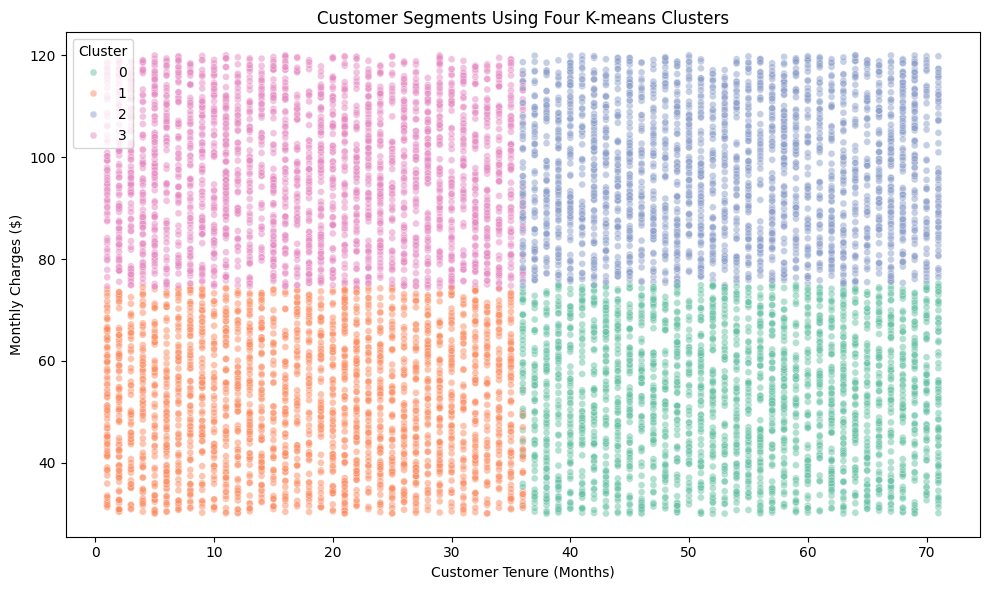

In [ ]:

# Convert the four-cluster results to Pandas
clusters_4_pdf = clusters_4.select(
    "Tenure",
    "Monthly_Charges",
    "Cluster"
).toPandas()

# Create a scatterplot for the four customer groups
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clusters_4_pdf,
    x="Tenure",
    y="Monthly_Charges",
    hue="Cluster",
    palette="Set2",
    alpha=0.5,
    s=25
)

# Add a title and labels
plt.title("Customer Segments Using Four K-means Clusters")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Monthly Charges ($)")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()


The four-cluster scatterplot shows how customers were grouped based on tenure and monthly charges. Compared to the three-cluster model, I can see the differences between the groups a little better. Customers were separated into groups based on how long they've been with the company and whether they have lower or higher monthly bills.

The silhouette score also went up from 0.4436 to 0.4588. It wasn't a big improvement, but four clusters worked slightly better.

One thing I noticed was that the churn rates were still pretty similar across all four groups. The clusters helped me understand the differences in customer spending and tenure, but they didn't really help identify which customers were more likely to leave.

## Conclusion

For this assignment, I used PySpark and scikit-learn to analyze 10,000 telecom customer records and predict which customers might leave the company.

The dataset was pretty clean to begin with. There were no missing values or negative numbers. I found 19 identical rows but decided to keep them because there were no customer IDs to confirm if they were duplicates.

When I looked at the data, I noticed that churn rates were almost the same across different service types, tenure groups, and monthly charges. About 20% of customers left in nearly every group.

The Logistic Regression results weren't what I expected. Both scikit-learn and PySpark had 80.35% accuracy, but neither model identified any customers who actually left. After balancing the class weights, recall improved to 48.85%, but accuracy dropped to 49.95%. The model was finding more customers who left, but it was also making more incorrect predictions.

I also used K-means to group customers based on their characteristics. I tested 2 through 5 clusters, and four gave me the best silhouette score at 0.4588. The groups had different spending amounts and tenure, but their churn rates were still pretty similar.

If I continued working on this project, I would want to include more information, like customer complaints, contract types, payment history, and support tickets. I would also like to try Random Forest and see if adjusting the classification threshold improves the predictions.

The biggest thing I learned was that high accuracy doesn't always mean a model is doing a good job. My models had over 80% accuracy but couldn't identify the customers I was actually trying to predict. I also learned that adding more clusters doesn't necessarily make the results more useful.

## References

Apache Software Foundation. (n.d.). MLlib: Main guide. Apache Spark. https://spark.apache.org/docs/latest/ml-guide.html
Apache Software Foundation. (n.d.). Clustering. Apache Spark. https://spark.apache.org/docs/latest/ml-clustering.html
Scikit-learn developers. (n.d.). Logistic regression. Scikit-learn. https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
Scikit-learn developers. (n.d.). Classification metrics. Scikit-learn. https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics
Scikit-learn developers. (n.d.). Silhouette coefficient. Scikit-learn. https://scikit-learn.org/stable/modules/clustering.html#silhouette-coefficient
Scikit-learn developers. (n.d.). LogisticRegression. Scikit-learn. https://